# Blockpose — Synthetic Scene Gallery

Visualize the declarative YAML scenes in `config/scenes/` and iterate on them quickly.

Each scene describes a storage/assembly scenario (loose staging blocks, stacks, walls, ...)
plus sensor and side-clutter settings; `blockpose.scenes` raycasts it into a point cloud with
exact ground truth. Edit a YAML (or add a new one) and re-run the gallery — or use
`show_scene_yaml("config/scenes/your_scene.yaml")` to render just that one.

> See `docs/detector-plan.md` for the scene schema, and `tools/view_scene.py` for a
> standalone (interactive) viewer.


In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "python"))

from blockpose.scenes import load_and_generate
from blockpose.detection import DetectionParams, detect_blocks
SCENES_DIR = REPO_ROOT / "config" / "scenes"
print("scenes found:", [p.name for p in sorted(SCENES_DIR.glob("*.yaml"))])


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


scenes found: ['stacked_blocks.yaml', 'storage_yard.yaml', 'wall.yaml']


## Rendering helper

`show_scene_yaml` loads a scene YAML, raycasts it, and renders the whole scene (point cloud
coloured by height + green ground-truth boxes). Pass `detect=True` to overlay the detector
output (blue). The view auto-fits, widening when side clutter is present.


In [2]:
def _box_edges(center, R, dims):
    dims = np.asarray(dims, float)
    signs = np.array([[sx, sy, sz] for sx in (-1, 1) for sy in (-1, 1) for sz in (-1, 1)])
    corners = (R @ (signs * dims / 2.0).T).T + np.asarray(center, float)
    edges = [(i, j) for i in range(8) for j in range(i + 1, 8) if bin(i ^ j).count("1") == 1]
    return [np.stack([corners[i], corners[j]]) for i, j in edges]


def _set_equal_3d(ax, arrays, padding=0.06, min_span=0.5):
    finite = [np.asarray(a, float).reshape(-1, 3) for a in arrays if np.asarray(a).size]
    points = np.vstack(finite) if finite else np.zeros((1, 3))
    points = points[np.all(np.isfinite(points), axis=1)]
    if not len(points):
        points = np.zeros((1, 3))
    low, high = points.min(0), points.max(0)
    spans = np.maximum(high - low, min_span) * (1.0 + 2.0 * padding)
    center = (low + high) / 2.0
    ax.set_xlim(center[0] - spans[0] / 2, center[0] + spans[0] / 2)
    ax.set_ylim(center[1] - spans[1] / 2, center[1] + spans[1] / 2)
    ax.set_zlim(center[2] - spans[2] / 2, center[2] + spans[2] / 2)
    ax.set_box_aspect(spans)


def _draw_boxes(ax, poses, color, label, dims):
    first = True
    for p in poses:
        for seg in _box_edges(p.position, p.rotation, dims):
            ax.plot(*seg.T, color=color, lw=2.0, label=label if first else None, zorder=5)
            first = False


def show_scene_yaml(path, detect=False, seed=0, elev=32, azim=-72, reach=None,
                    subsample=24000, ax=None):
    """Load a scene YAML, raycast it, and render the whole scene (+ optional detections)."""
    cfg, pts, gt = load_and_generate(path, np.random.default_rng(seed))
    dims = cfg.specs[0].dims if cfg.specs else (0.6, 0.6, 0.9)
    det = detect_blocks(pts, DetectionParams()) if detect else None

    centers = np.array([p.position for p in gt])
    ctr = centers.mean(0) if len(centers) else pts.mean(0)
    if reach is None:
        spread = float(np.abs(centers[:, :2] - ctr[:2]).max()) if len(centers) else 1.0
        reach = spread + (5.0 if cfg.clutter is not None else 1.5)

    keep = (np.abs(pts[:, 0] - ctr[0]) < reach) & (np.abs(pts[:, 1] - ctr[1]) < reach)
    p = pts[keep]
    if len(p) > subsample:
        p = p[np.random.default_rng(0).choice(len(p), subsample, replace=False)]

    own = ax is None
    if own:
        fig = plt.figure(figsize=(10, 6.5))
        ax = fig.add_subplot(111, projection="3d")
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], cmap="turbo", s=3, alpha=0.6, depthshade=False)
    _draw_boxes(ax, gt, "#00e000", "ground truth", dims)
    if det:
        _draw_boxes(ax, det, "#1e78ff", "detected", dims)

    box_points = [seg for pose in [*gt, *(det or [])] for seg in _box_edges(pose.position, pose.rotation, dims)]
    _set_equal_3d(ax, [p, *box_points])
    title = f"{cfg.name}: {len(pts)} pts, {len(gt)} blocks"
    if det is not None:
        title += f", {len(det)} detected"
    ax.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]", title=title)
    ax.view_init(elev=elev, azim=azim)
    ax.legend(loc="upper left")
    if own:
        plt.tight_layout()
        plt.show()
    return cfg, pts, gt, det

print("helper ready")


helper ready


## The gallery — every scene in `config/scenes/`

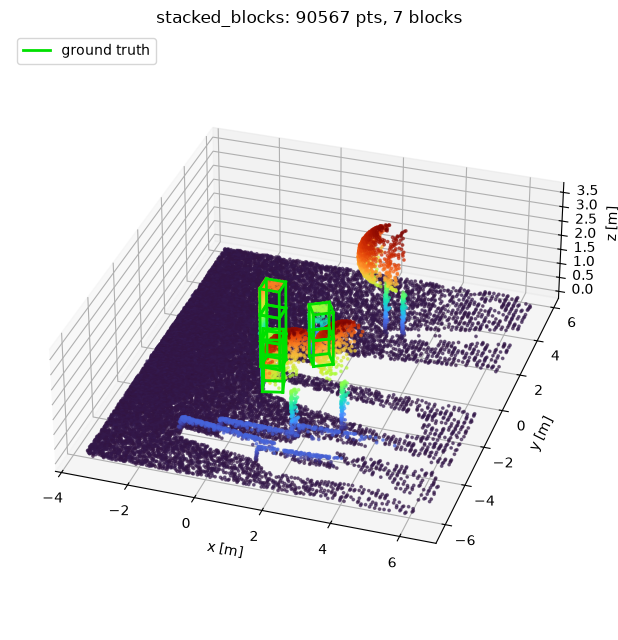

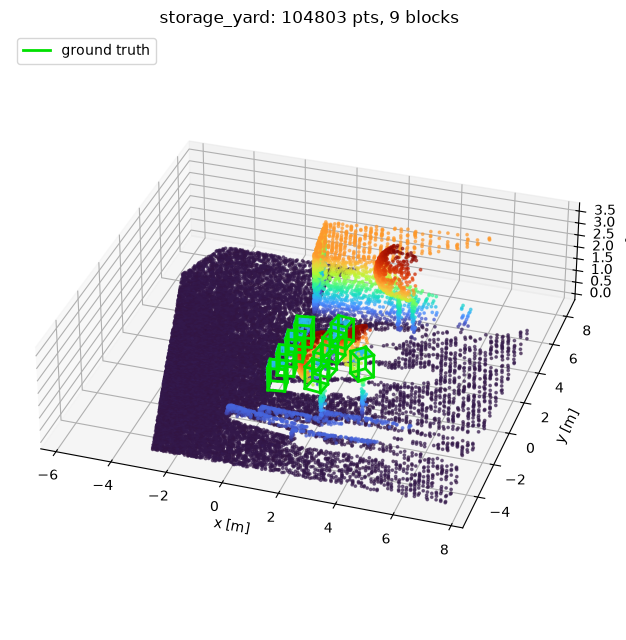

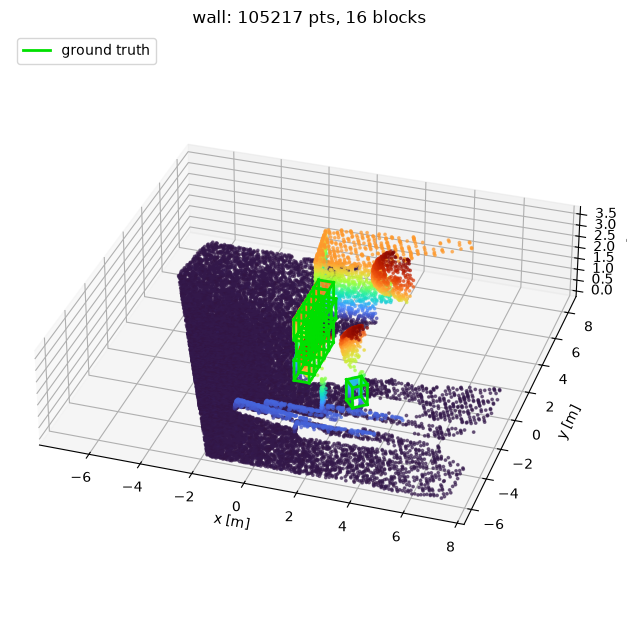

In [3]:
for path in sorted(SCENES_DIR.glob("*.yaml")):
    show_scene_yaml(path)


## Detector overlay

Overlay the detector output (blue) on ground truth (green). Note the **wall** is a solid run
of adjacent blocks — the current plane-based `DetectFree` merges it into one cluster and does
not split it (that is Phase-C `VerifyPlaced` / wall handling), so few/no detections appear
there. Isolated staging blocks and separated stacks detect well.


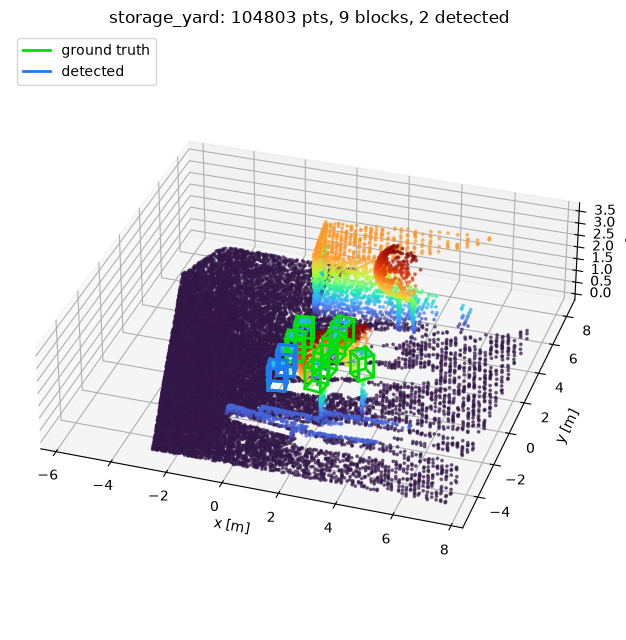

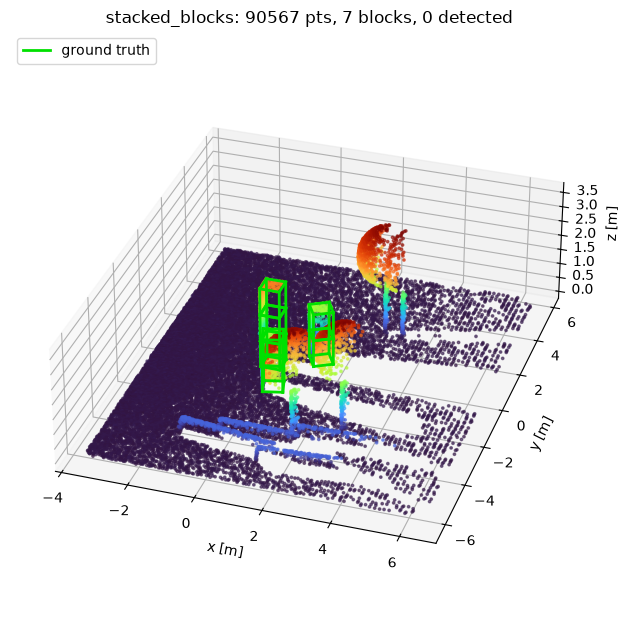

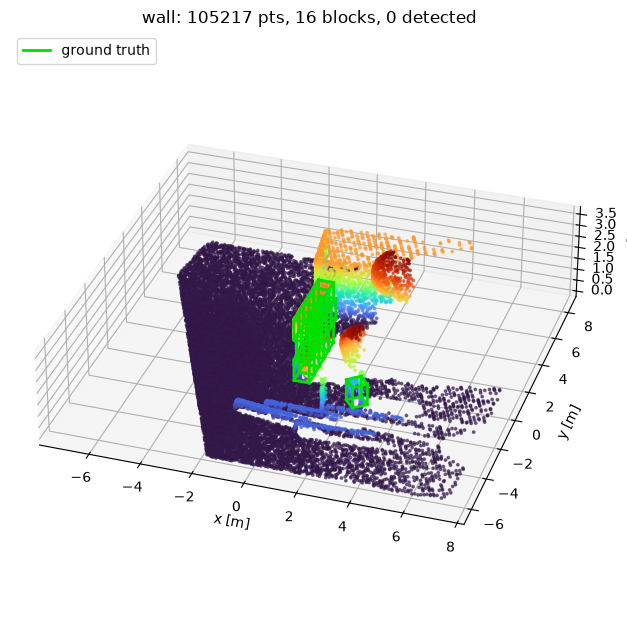

In [4]:
for name in ["storage_yard", "stacked_blocks", "wall"]:
    show_scene_yaml(SCENES_DIR / f"{name}.yaml", detect=True)


## Iterate

Edit a YAML in `config/scenes/` (or add a new one) and re-render a single scene:

```python
show_scene_yaml(SCENES_DIR / "wall.yaml", detect=True, elev=20, azim=-90)
```

Handy knobs: `detect` (overlay detections), `elev` / `azim` (camera angle), `reach` (view
half-width, m), `seed` (noise / clutter placement). The scene schema lives in
`docs/detector-plan.md`; patterns are `row`, `stack`, and `wall`.


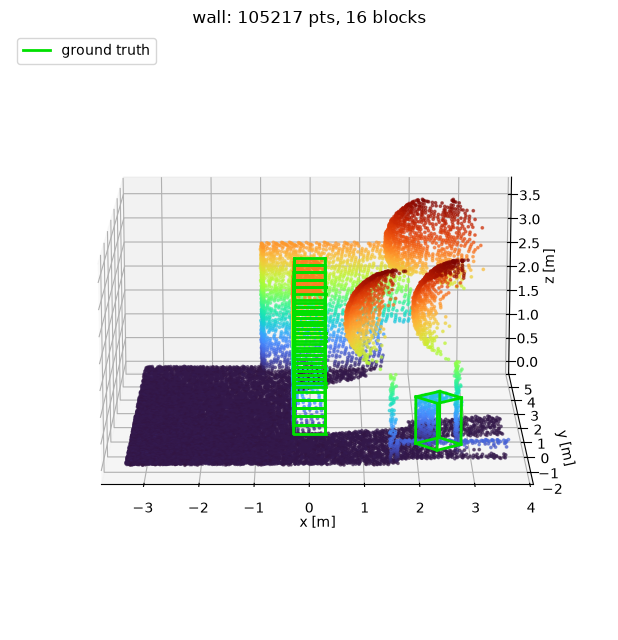

In [5]:
# Example: a closer, side-on look at the wall courses.
_ = show_scene_yaml(SCENES_DIR / "wall.yaml", elev=14, azim=-90, reach=3.5)


## Interactive inspection — detections vs ground truth

The renders above are fixed projections, which is fine for browsing scene definitions but poor
for judging *why* a detection sits where it does. The view below is interactive: **drag to
rotate, scroll to zoom, double-click to reset.**

Ground truth is <span style="color:#00c853">**green**</span>, the detector output is
<span style="color:#2979ff">**blue**</span>, and the sensor is the
<span style="color:#ff6d00">**orange diamond**</span> — the same convention as
`tools/view_scene.py`. Where the two wireframes coincide the detection is correct to well under
the line width.

Change `SCENE` to any file in `config/scenes/` and re-run. Try `wall`: the detector recovers
almost none of it, because blocks laid in contact present no measurable interface. That is the
single largest open gap and it is tracked as the `assembly` family in the scenario matrix.

In [6]:
from blockpose.detection import DetectionParams, detect_scene_sample
from blockpose.scenes import generate_from_config, load_scene_config
from blockpose.viz import error_table, sample_figure

SCENE = "storage_yard"          # try: wall, stacked_blocks, storage_yard

# Pass the whole sample, not just points: without the sensor origin and rays the
# detector loses range-adaptive density scaling and free-space evidence, which
# on this scene alone drops recall from 9/9 to 1/9.
cfg = load_scene_config(SCENES_DIR / f"{SCENE}.yaml")
sample = generate_from_config(cfg, np.random.default_rng(0))
ground_truth = sample.ground_truth
detections = detect_scene_sample(sample, DetectionParams())

print(f"{SCENE}: {len(ground_truth)} ground-truth blocks, {len(detections)} detections")
for row in error_table(detections, ground_truth):
    if row["detection"] is None:
        print(f"   gt[{row['gt']:2d}]  MISSED")
    else:
        print(f"   gt[{row['gt']:2d}]  {row['translation_mm']:7.2f} mm"
              f"   {row['rotation_deg']:5.2f} deg")

sample_figure(
    sample,
    detections,
    title=f"{SCENE} — ground truth vs detections",
    max_points=6000,
)

storage_yard: 9 ground-truth blocks, 9 detections
   gt[ 0]     0.89 mm    0.33 deg
   gt[ 1]     2.29 mm    0.17 deg
   gt[ 2]     0.94 mm    0.29 deg
   gt[ 3]     0.59 mm    0.12 deg
   gt[ 4]     0.94 mm    0.05 deg
   gt[ 5]     0.23 mm    0.25 deg
   gt[ 6]     2.36 mm    0.23 deg
   gt[ 7]     0.86 mm    0.16 deg
   gt[ 8]     0.47 mm    0.19 deg
